In [1]:
from environment import benchmark, F1TenthEnv, RoboRacerEnv
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import time


/Users/jacquesamsel/.pyenv/versions/skripsie2/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
f1tenth_env = F1TenthEnv(num_stacked_frames=50)

objc[75804]: Class SDLApplication is implemented in both /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x1208cc890) and /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1428f92c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[75804]: Class SDLAppDelegate is implemented in both /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x1208cc8e0) and /Users/jacquesamsel/.pyenv/versions/3.10.12/envs/skripsie2/lib/python3.10/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x1428f9318). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[75804]: Class SDLTranslatorResponder is implemented in both /Users/jacquesamsel/.pyenv/versions/3.1

In [3]:
time.sleep(10)
f1tenth_env_benchmark = benchmark(f1tenth_env, reset_in_python=True)
time.sleep(10)

100%|██████████| 10000/10000 [00:27<00:00, 363.10it/s]


In [4]:
del f1tenth_env

In [5]:
unity_env = RoboRacerEnv(file_name="TestUnityProject/Test Speed/build.app", num_areas=1, num_stacked_frames=50, worker_id=1)

I1014 14:11:38.551772 13005376 fork_posix.cc:71] Other threads are currently calling into gRPC, skipping fork() handlers
I1014 14:11:38.558130 13007597 ev_poll_posix.cc:587] FD from fork parent still in poll list: fd(98, generation: 1)


[UnityMemory] Configuration Parameters - Can be set up in boot.config
    "memorysetup-temp-allocator-size-nav-mesh-worker=65536"
    "memorysetup-temp-allocator-size-cloud-worker=32768"
    "memorysetup-temp-allocator-size-audio-worker=65536"
    "memorysetup-allocator-temp-initial-block-size-main=262144"
    "memorysetup-allocator-temp-initial-block-size-worker=262144"
    "memorysetup-temp-allocator-size-preload-manager=262144"
    "memorysetup-temp-allocator-size-gfx=262144"
    "memorysetup-temp-allocator-size-background-worker=32768"
    "memorysetup-temp-allocator-size-job-worker=262144"
    "memorysetup-bucket-allocator-granularity=16"
    "memorysetup-bucket-allocator-bucket-count=8"
    "memorysetup-bucket-allocator-block-size=4194304"
    "memorysetup-bucket-allocator-block-count=1"
    "memorysetup-main-allocator-block-size=16777216"
    "memorysetup-thread-allocator-block-size=16777216"
    "memorysetup-main-allocator-mimalloc-enabled=0"
    "memorysetup-gfx-main-allocator

In [6]:
unity_env_benchmark = benchmark(unity_env, reset_in_python=False)

100%|██████████| 10000/10000 [00:32<00:00, 305.69it/s]


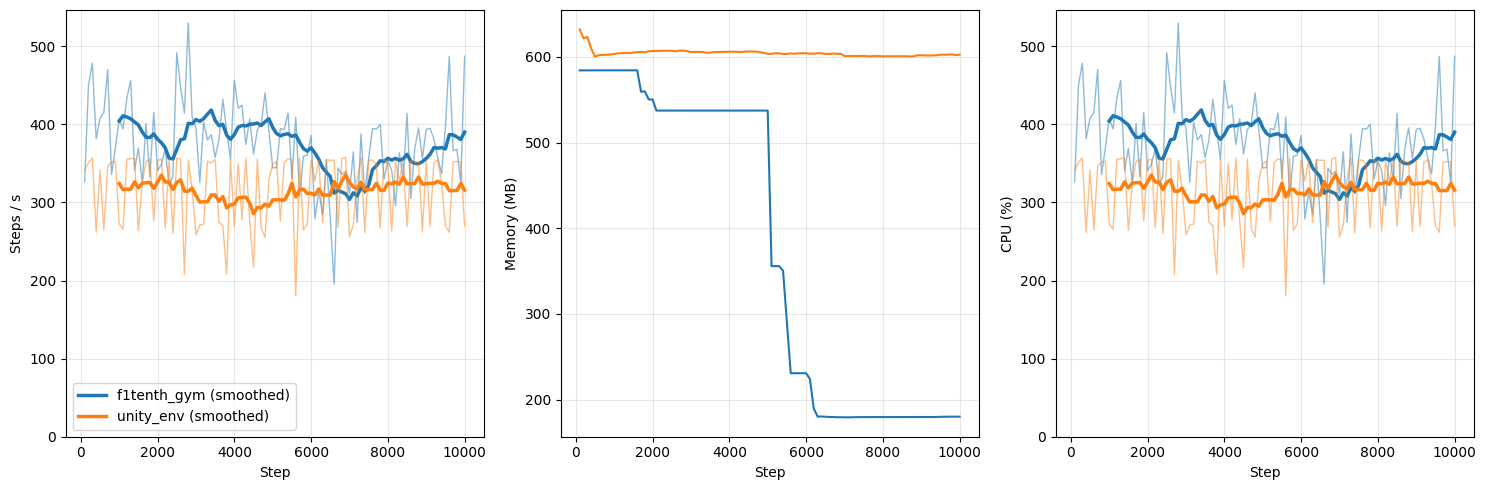

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = [("sps", "Steps / s"), ("mem_mb", "Memory (MB)"), ("cpu", "CPU (%)")]
runs = {"f1tenth_gym": f1tenth_env_benchmark, "unity_env": unity_env_benchmark}
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for (name, log), color in zip(runs.items(), colors):
    for ax, (key, label) in zip(axes, metrics):
        if key == "sps" or key =="cpu":
            sps = pd.Series(log["sps"])
            ax.plot(log["step"], sps, color=color, alpha=0.5, linewidth=1)
            ax.plot(log["step"], sps.rolling(10).mean(), color=color, linewidth=2.5,
                    label=f"{name} (smoothed)")
            ax.set_ylim(bottom=0)
        else:
            ax.plot(log["step"], log[key], color=color, label=name)
        ax.set_ylabel(label)
        ax.set_xlabel("Step")
        ax.grid(alpha=0.3)


axes[0].legend()
fig.tight_layout()
#plt.show()
plt.savefig("results/sim_benchmarks.pdf")

In [8]:
unity_env_benchmark['mem_mb'].mean() -  \
f1tenth_env_benchmark['mem_mb'].mean()

np.float64(226.53687499999995)